In [462]:
import euclidlib as el
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import integrate
from copy import deepcopy
import seaborn as sns

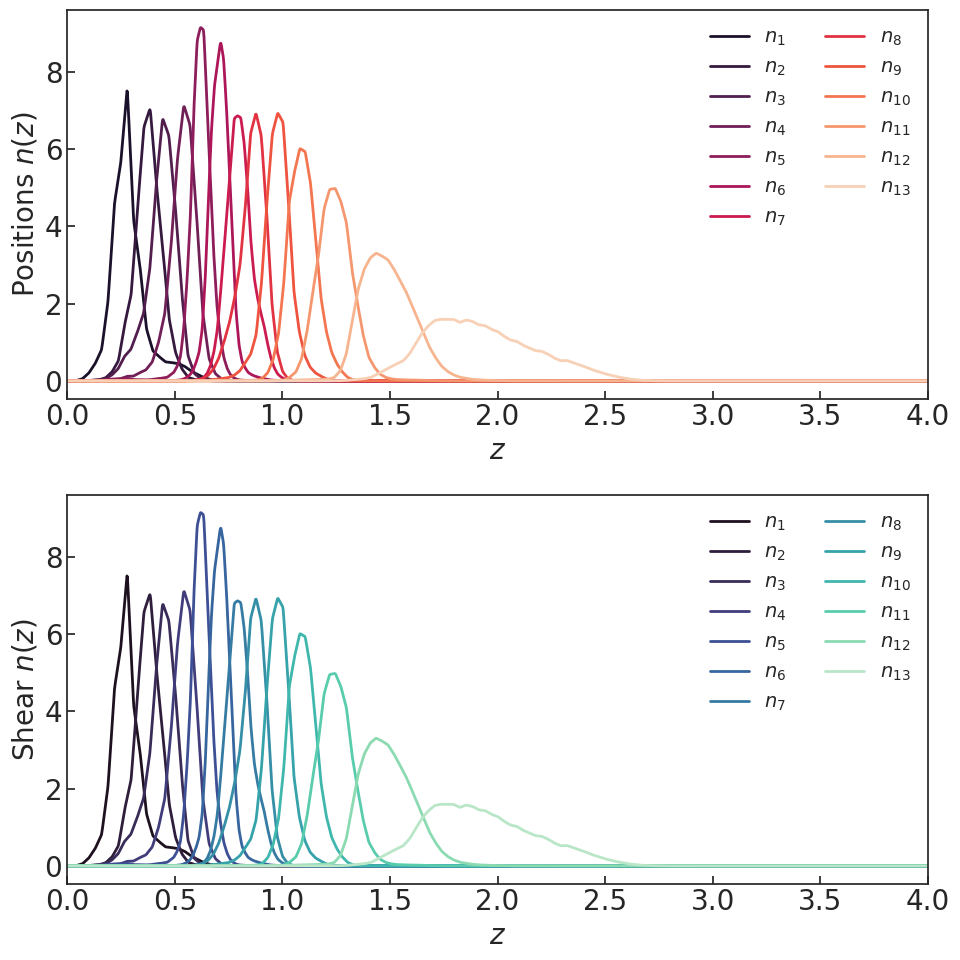

In [463]:

zs = np.linspace(1e-4, 3, 100)

z, nz = el.photo.redshift_distributions('/home/jipdebuck/nzTabSPV3.fits')

def normalize_dndz(nz_example, z_nz):
    normalized = {}
    for key in nz_example:
        normalized[key] = nz_example[key] / integrate.trapezoid(nz_example[key], z_nz)
    return normalized

# Normalize both dndz_pos and dndz_she
dndz_pos_norm = normalize_dndz(nz, z)
dndz_she_norm = normalize_dndz(nz, z)

# Function to resample the normalized dndz
def resample_dndz(nz_example, z_nz, myz):
    my_dndz = np.vstack(list(nz_example.values())) #stacking arrays vertically
    my_dndz_norm = np.zeros([len(nz_example), len(myz)]) #creating an empty array
    for i in range(len(nz_example)):
        my_dndz_norm[i, :] = np.interp(myz, z_nz, my_dndz[i, :]) #interpolating to new myz values
    return my_dndz_norm

# Resampling the normalized dndz with 100 values
my_dndz_pos_norm = resample_dndz(dndz_pos_norm, z, zs)
my_dndz_she_norm = resample_dndz(dndz_she_norm, z, zs)

# Plotting dndz
fig, axs = plt.subplots(2, 1, figsize=(10, 10))

# Customize tick parameters for both axes
for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')

# Plot positions n(z)
for i, (key, color) in enumerate(zip(dndz_pos_norm.keys(), sns.color_palette("rocket", len(dndz_pos_norm)))):
    axs[0].plot(z, dndz_pos_norm[key], label=f'$n_{{{i+1}}}$', linewidth=2, color=color)

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs[1].plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)

# Set labels and legends
axs[0].set_xlabel(r'$z$')
axs[0].set_ylabel(r'Positions $n(z)$')
axs[0].set_xlim(0, 4)
axs[0].legend(frameon=False, ncol=2)

axs[1].set_xlabel(r'$z$')
axs[1].set_ylabel(r'Shear $n(z)$')
axs[1].set_xlim(0, 4)
axs[1].legend(frameon=False, ncol=2)

plt.tight_layout()
plt.show()

20 20


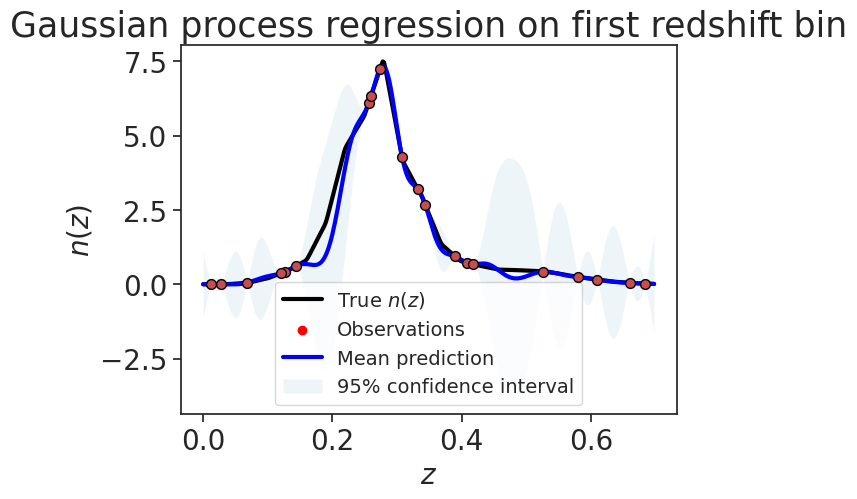

In [464]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

rng = np.random.RandomState(4)
z_range = (0, 0.7)
z_indces = np.where((z >= z_range[0]) & (z <= z_range[1]))[0]
z_1 = z[z_indces]
dndz_she_1 = dndz_she_norm[1][z_indces]
training_indices = rng.choice(np.arange(z_1.size), size=20, replace=False)
X_train, y_train = z_1[training_indices].reshape(-1,1), dndz_she_1[training_indices]
print(len(X_train), len(y_train))
plt.scatter(X_train, y_train, c='r', s=50, zorder=10, edgecolors=(0, 0, 0))

kernel =  C(1.0, (1e-3, 1e3)) * RBF(length_scale=2, length_scale_bounds=(1e-2, 1.0))
gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=9)
gaussian_process.fit(X_train, y_train)
gaussian_process.kernel_

mean_prediction, std_prediction = gaussian_process.predict(z_1.reshape(-1,1), return_std=True)

plt.plot(z_1, dndz_she_1, c='black', label="True $n(z)$")
plt.scatter(X_train, y_train, c='red', label="Observations")
plt.plot(z_1, mean_prediction, c='blue', label="Mean prediction")
plt.fill_between(
    z_1.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    alpha=0.2,
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$z$")
plt.ylabel("$n(z)$")
_ = plt.title("Gaussian process regression on first redshift bin")


z_centers: {1: array([0.08      , 0.63      , 0.27590319]), 2: array([0.184    , 0.56     , 0.3766136]), 3: array([0.192     , 0.61      , 0.44582912]), 4: array([0.27      , 0.706     , 0.54241966]), 5: array([0.468     , 0.77      , 0.62147485]), 6: array([0.558     , 0.886     , 0.70939806]), 7: array([0.638     , 0.994     , 0.79856575]), 8: array([0.642     , 1.02      , 0.86666092]), 9: array([0.758     , 1.186     , 0.97796899]), 10: array([0.914     , 1.302     , 1.09136353]), 11: array([1.036     , 1.476     , 1.24322479]), 12: array([1.244     , 1.822     , 1.47931666]), 13: array([1.416     , 2.562     , 1.89292361])}
n_at_centers: {1: array([0.        , 0.        , 7.38783932]), 2: array([0.        , 0.        , 6.89124298]), 3: array([0.        , 0.        , 6.75850344]), 4: array([0.        , 0.        , 7.08562136]), 5: array([0.        , 0.        , 9.13497829]), 6: array([0.        , 0.        , 8.66318512]), 7: array([0.        , 0.        , 6.83832932]), 8: array([0.

/home/jipdebuck/miniconda3/envs/shared_env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 0.01. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/jipdebuck/miniconda3/envs/shared_env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.01. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Text(0, 0.5, '$n(z)$')

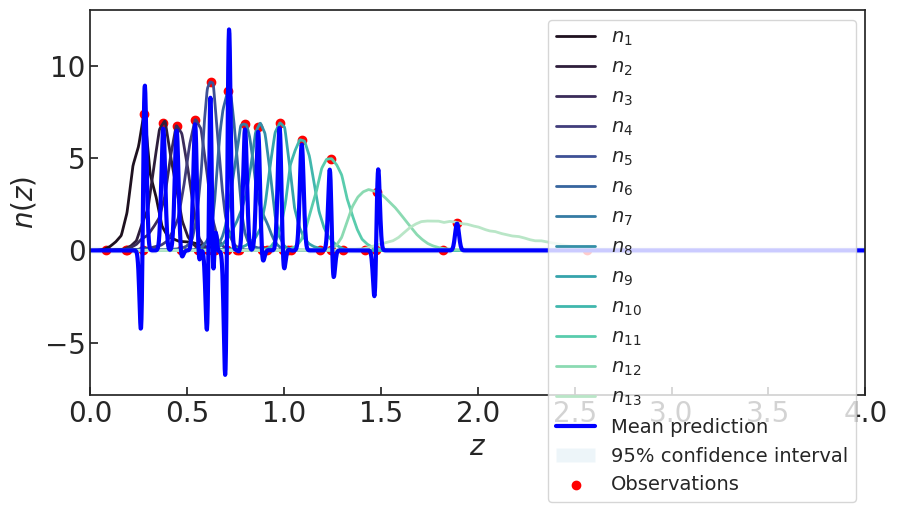

In [465]:
#Find redshift distribution using one training node per bin and correlation lengths'
cdfs = {}

for key in nz.keys():
    #cumulative integral of n(z)
    cdf = integrate.cumulative_trapezoid(nz[key], z, initial=0)
    
    #normalize so that CDF goes from 0 → 1
    cdf /= cdf[-1]
    
    cdfs[key] = cdf

z_centers = {}
for key in nz.keys():
    z_center = np.interp(0.5, cdfs[key], z)
    
    # store median in dictionary
    z_centers[key] = np.array([z_center])   # 1D array
    
    # edges: first and last z where n(z) > 0.1
    mask = nz[key] > 0.1
    z_edge_vals = np.array([z[mask][0], z[mask][-1]])  # left & right edges
    
    # combine edges and center into one array
    z_centers[key] = np.concatenate([z_edge_vals, z_centers[key]])

print('z_centers:', z_centers)  

n_at_centers = {}

for key in nz.keys():
    # nz[key] = array of n(z) values on a fine z grid
    # z_centers[key] = array of bin centers for this sample
    min_index = np.argmin(np.abs(z - z_centers[key][2]))
    
    # extract the n(z) value at that index
    n_center_value = np.array([nz[key][min_index]])  # make it 1D array
    
    # create zeros for baseline at edges
    n_zeros = np.zeros(2)  # left and right edges
    
    # concatenate zeros and n_center_value
    n_at_centers[key] = np.concatenate([n_zeros, n_center_value])

print('n_at_centers:', n_at_centers)
print('z_centers:', z_centers)

n_means = {}
for key in nz.keys():
    bin_indx = nz[key] > 0.1
    n_mean = np.mean(nz[key][bin_indx])
    n_means[key] = n_mean   


X = np.array([z_centers[key] for key in nz.keys()]).reshape(-1,1)
y = np.array([n_at_centers[key] for key in nz.keys()])
y = np.concatenate(y)
print(X, y)

sigma_obs = 0.02 * np.ones_like(y)
kernel = C(0.01, (0.001, 0.01)) * RBF(length_scale=0.5, length_scale_bounds=(0.01, 10))
gp = GaussianProcessRegressor(kernel=kernel, alpha=sigma_obs**2, n_restarts_optimizer=0, normalize_y=False)
gp.fit(X,y)

z_pred = np.linspace(0, 3, 500).reshape(-1,1)
y_pred, y_std = gp.predict(z.reshape(-1,1), return_std=True)

fig, axs = plt.subplots(1, 1, figsize=(10, 5))

# Customize tick parameters for both axes

axs.tick_params(axis='both', which='both', direction='in')

# Plot shear n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    axs.plot(z, dndz_she_norm[key], label=f'$n_{{{j+1}}}$', linewidth=2, color=color)


axs.set_xlabel(r'$z$')
axs.set_ylabel(r'Shear $n(z)$')
axs.set_xlim(0, 4)
axs.legend(loc='right')




axs.plot(z, y_pred, c='blue', label="Mean prediction")
axs.fill_between(
    z.ravel(),
    y_pred - 1.96 * y_std,
    y_pred + 1.96 * y_std,
    alpha=0.2,
    label=r"95% confidence interval",
)
axs.scatter(X, y, c='red', label="Observations")
axs.legend()
axs.set_xlabel("$z$")
axs.set_ylabel("$n(z)$")

z_centers: {1: 0.2759031918083645, 2: 0.3766135980633325, 3: 0.4458291163626341, 4: 0.5424196599332396, 5: 0.62147485082995, 6: 0.7093980586687245, 7: 0.7985657465222972, 8: 0.8666609167150825, 9: 0.977968986175267, 10: 1.0913635348981672, 11: 1.2432247854803824, 12: 1.4793166613053534, 13: 1.892923607877304}
n_at_centers: {1: 7.3878393, 2: 6.891243, 3: 6.7585034, 4: 7.0856214, 5: 9.134978, 6: 8.663185, 7: 6.8383293, 8: 6.687738, 9: 6.9103985, 10: 5.9762745, 11: 4.9754233, 12: 3.169097, 13: 1.5132651}
Optimized kernel: 1**2 * RBF(length_scale=0.0343)


/home/jipdebuck/miniconda3/envs/shared_env/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


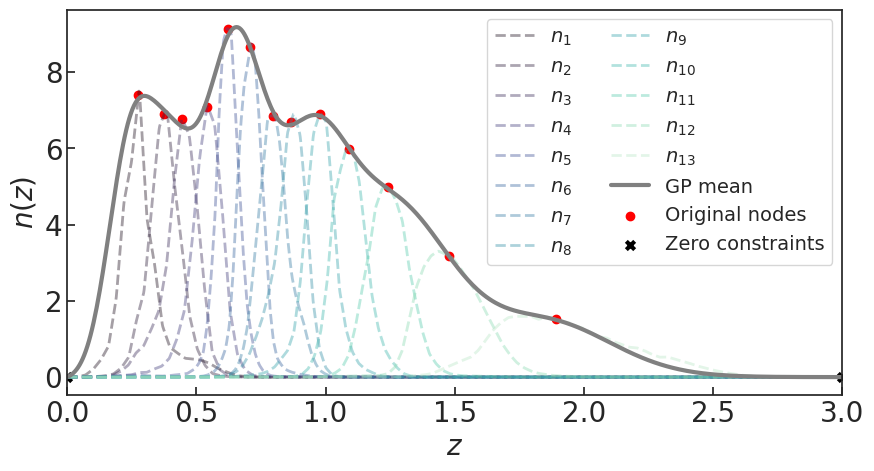

In [466]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
import seaborn as sns
from scipy import integrate

l = 0.003

# --- Compute CDFs ---
cdfs = {key: integrate.cumulative_trapezoid(nz[key], z, initial=0) / integrate.cumulative_trapezoid(nz[key], z, initial=0)[-1]
        for key in nz.keys()}

# --- Find median z for each n(z) ---
z_centers = {key: np.interp(0.5, cdfs[key], z) for key in nz.keys()}
print("z_centers:", z_centers)

# --- Get n(z) values at those centers ---
n_at_centers = {key: nz[key][np.argmin(np.abs(z - z_centers[key]))] for key in nz.keys()}
print("n_at_centers:", n_at_centers)

# --- Prepare data for GP ---
X = np.array([z_centers[key] for key in nz.keys()]).reshape(-1, 1)
y = np.array([n_at_centers[key] for key in nz.keys()])

# --- Enforce GP to return to zero at edges ---
z_min, z_max = 0.0, 3.0
X_aug = np.vstack((np.array([[z_min], [z_max]]), X))      # Add boundary points
y_aug = np.hstack(([0.0, 0.0], y))          # Set n(z)=0 at edges

# --- Train GP ---
kernel = C(0.01, (0.001, 1)) * RBF(length_scale=l, length_scale_bounds=(1e-5, 1e5))
gp = GaussianProcessRegressor(kernel=kernel, alpha=0.01, normalize_y=False)
gp.fit(np.log10(1 + X_aug), y_aug)
print("Optimized kernel:", gp.kernel_)

# --- Predict ---
z_pred = np.linspace(z_min, z_max, 500).reshape(-1, 1)
y_pred, y_std = gp.predict(np.log10(1 + z_pred), return_std=True)

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.tick_params(axis='both', which='both', direction='in')

# Plot original n(z)
for j, (key, color) in enumerate(zip(dndz_she_norm.keys(), sns.color_palette("mako", len(dndz_she_norm)))):
    ax.plot(z, dndz_she_norm[key], '--', alpha=0.4, linewidth=2, color=color, label=f'$n_{{{j+1}}}$')

ax.plot(z_pred, y_pred, c='grey', label="GP mean")
ax.scatter(X, y, c='red', label="Original nodes")
ax.scatter([z_min, z_max], [0, 0], c='black', marker='x', label="Zero constraints")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(z_min, z_max)
ax.legend(loc='upper right', ncol=2)
plt.show()



## Guada's try:

Do x-number of gaussian processes but a global correlation length (to reduce number of parameters)


GP prior for 1: z_med=0.276, n_med=7.388, width=0.136, corr_length=0.014
GP prior for 2: z_med=0.377, n_med=6.892, width=0.121, corr_length=0.012
GP prior for 3: z_med=0.446, n_med=6.759, width=0.130, corr_length=0.013
GP prior for 4: z_med=0.542, n_med=7.086, width=0.117, corr_length=0.012
GP prior for 5: z_med=0.621, n_med=9.135, width=0.087, corr_length=0.009
GP prior for 6: z_med=0.709, n_med=8.664, width=0.090, corr_length=0.009
GP prior for 7: z_med=0.799, n_med=6.838, width=0.119, corr_length=0.012
GP prior for 8: z_med=0.867, n_med=6.688, width=0.125, corr_length=0.012
GP prior for 9: z_med=0.978, n_med=6.911, width=0.115, corr_length=0.011
GP prior for 10: z_med=1.091, n_med=5.976, width=0.129, corr_length=0.013
GP prior for 11: z_med=1.243, n_med=4.976, width=0.156, corr_length=0.016
GP prior for 12: z_med=1.479, n_med=3.169, width=0.239, corr_length=0.024
GP prior for 13: z_med=1.893, n_med=1.513, width=0.518, corr_length=0.052


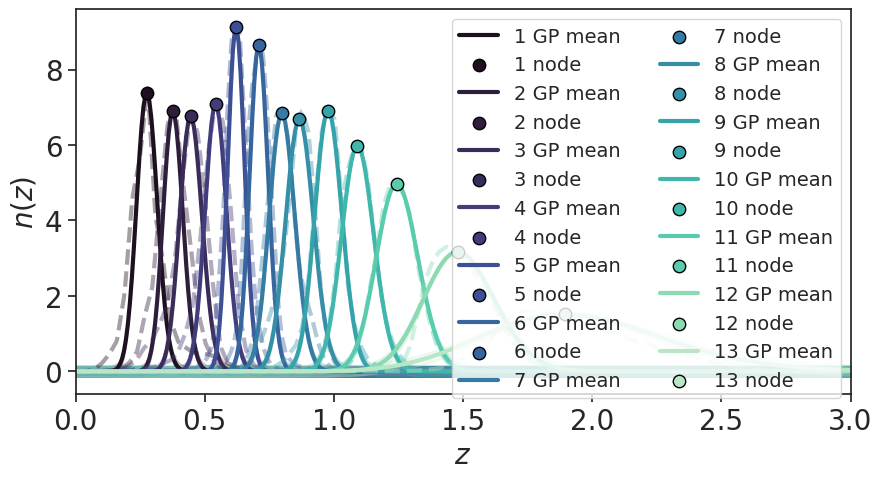

In [467]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from scipy import integrate
import seaborn as sns

z_min, z_max = 0.0, 3.0
z_pred = np.linspace(z_min, z_max, 400).reshape(-1, 1)
corr_length = 0.1  # correlation length factor (relative to bin width)
sigma_amp = 0.02    # GP amplitude

gp_priors = {}
gp_predictions = {}
training_nodes = {}

for key, nz in dndz_she_norm.items():
    # --- Compute CDF & median ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]

    # --- Estimate width (for scaling correlation length) ---
    z_low = np.interp(0.16, cdf, z)
    z_high = np.interp(0.84, cdf, z)
    width = z_high - z_low

    # --- Define kernel ---
    kernel = C(sigma_amp, (1e-4, 1)) * RBF(length_scale=corr_length * width, length_scale_bounds="fixed")

    # --- Define GP prior (no fitting to full data) ---
    gp = GaussianProcessRegressor(kernel=kernel, optimizer=None, normalize_y=False)

    # --- Use the median as the training node ---
    X_train = np.array([[z_med]])
    y_train = np.array([n_med])
    gp.fit(np.log10(1 + X_train), y_train)

    # --- Predict GP mean and std ---
    y_pred, y_std = gp.predict(np.log10(1 + z_pred), return_std=True)

    gp_priors[key] = gp
    gp_predictions[key] = (y_pred, y_std)
    training_nodes[key] = (X_train, y_train)

    print(f"GP prior for {key}: z_med={z_med:.3f}, n_med={n_med:.3f}, width={width:.3f}, corr_length={corr_length * width:.3f}")

# --- Plot ---
palette = sns.color_palette("mako", len(dndz_she_norm))
fig, ax = plt.subplots(figsize=(10, 5))

for j, key in enumerate(dndz_she_norm.keys()):
    y_pred, y_std = gp_predictions[key]
    X_train, y_train = training_nodes[key]

    # GP prior mean + uncertainty
    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    ax.fill_between(z_pred.ravel(), y_pred - y_std, y_pred + y_std, color=palette[j], alpha=0.2)

    # Original n(z)
    ax.plot(z, dndz_she_norm[key], '--', color=palette[j], alpha=0.4)

    # Training node (median)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{key} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(z_min, z_max)
ax.legend(loc="upper right", ncol=2)
plt.show()


A bit more refined version:

1: z_med=0.276, n_med=7.388, ell(log-norm)=0.030
2: z_med=0.377, n_med=6.892, ell(log-norm)=0.030
3: z_med=0.446, n_med=6.759, ell(log-norm)=0.030
4: z_med=0.542, n_med=7.086, ell(log-norm)=0.030
5: z_med=0.621, n_med=9.135, ell(log-norm)=0.030
6: z_med=0.709, n_med=8.664, ell(log-norm)=0.030
7: z_med=0.799, n_med=6.838, ell(log-norm)=0.030
8: z_med=0.867, n_med=6.688, ell(log-norm)=0.030
9: z_med=0.978, n_med=6.911, ell(log-norm)=0.030
10: z_med=1.091, n_med=5.976, ell(log-norm)=0.030
11: z_med=1.243, n_med=4.976, ell(log-norm)=0.030
12: z_med=1.479, n_med=3.169, ell(log-norm)=0.030
13: z_med=1.893, n_med=1.513, ell(log-norm)=0.030


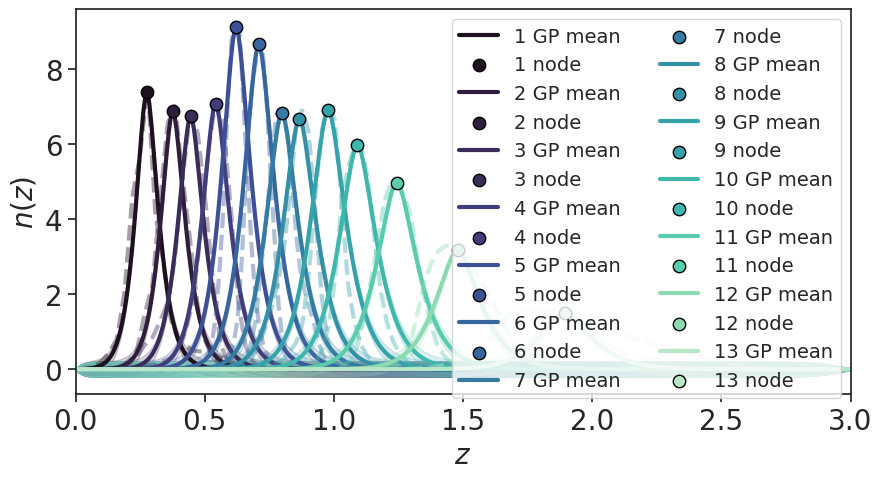

In [468]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy import integrate
import seaborn as sns

# Inputs you already have:
# z = np.linspace(0, 3, 200)
# dndz_she_norm = {"bin1": n1, "bin2": n2, ...}

z_min, z_max = 0.0, 3.0
z_pred = np.linspace(z_min, z_max, 400).reshape(-1, 1)

# ---- Global settings (one lengthscale only) ----
ell = 0.03        # single global correlation length in normalized log-space
sigma_amp = 0.04  # GP amplitude
alpha_jitter = 1e-8  # small nugget for stability

# Normalized log-space coordinate
def zx(z):
    return np.log1p(z) / np.log1p(z_max)

x_pred = zx(z_pred)

gp_priors = {}
gp_predictions = {}
training_nodes = {}

for key, nz in dndz_she_norm.items():
    # --- CDF & median node ---
    cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
    cdf /= cdf[-1]
    z_med = np.interp(0.5, cdf, z)
    n_med = nz[np.argmin(np.abs(z - z_med))]

    # --- Single global kernel (no widths) ---
    # Matérn is a bit less "too-smooth" than RBF
    kernel = C(sigma_amp, (1e-4, 1.0)) * Matern(length_scale=ell, nu=1.5, length_scale_bounds="fixed")

    gp = GaussianProcessRegressor(kernel=kernel, optimizer=None, normalize_y=False, alpha=alpha_jitter)

    # --- Universal boundary anchors + median node (no widths) ---
    X_train = np.array([[zx(z_min)], [zx(z_med)], [zx(z_max)]])
    y_train = np.array([0.0, n_med, 0.0])

    gp.fit(X_train, y_train)

    y_pred, y_std = gp.predict(x_pred, return_std=True)

    gp_priors[key] = gp
    gp_predictions[key] = (y_pred, y_std)
    training_nodes[key] = (np.array([[z_med]]), np.array([n_med]))

    print(f"{key}: z_med={z_med:.3f}, n_med={n_med:.3f}, ell(log-norm)={ell:.3f}")

# --- Plot like your example ---
palette = sns.color_palette("mako", len(dndz_she_norm))
fig, ax = plt.subplots(figsize=(10, 5))

for j, key in enumerate(dndz_she_norm.keys()):
    y_pred, y_std = gp_predictions[key]
    X_train, y_train = training_nodes[key]

    ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} GP mean")
    ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(), (y_pred + y_std).ravel(),
                    color=palette[j], alpha=0.2)

    ax.plot(z, dndz_she_norm[key], '--', color=palette[j], alpha=0.4)
    ax.scatter(X_train, y_train, color=palette[j], edgecolor='black', s=80, zorder=3, label=f"{key} node")

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$n(z)$")
ax.set_xlim(z_min, z_max)
ax.legend(loc="upper right", ncol=2)
plt.show()

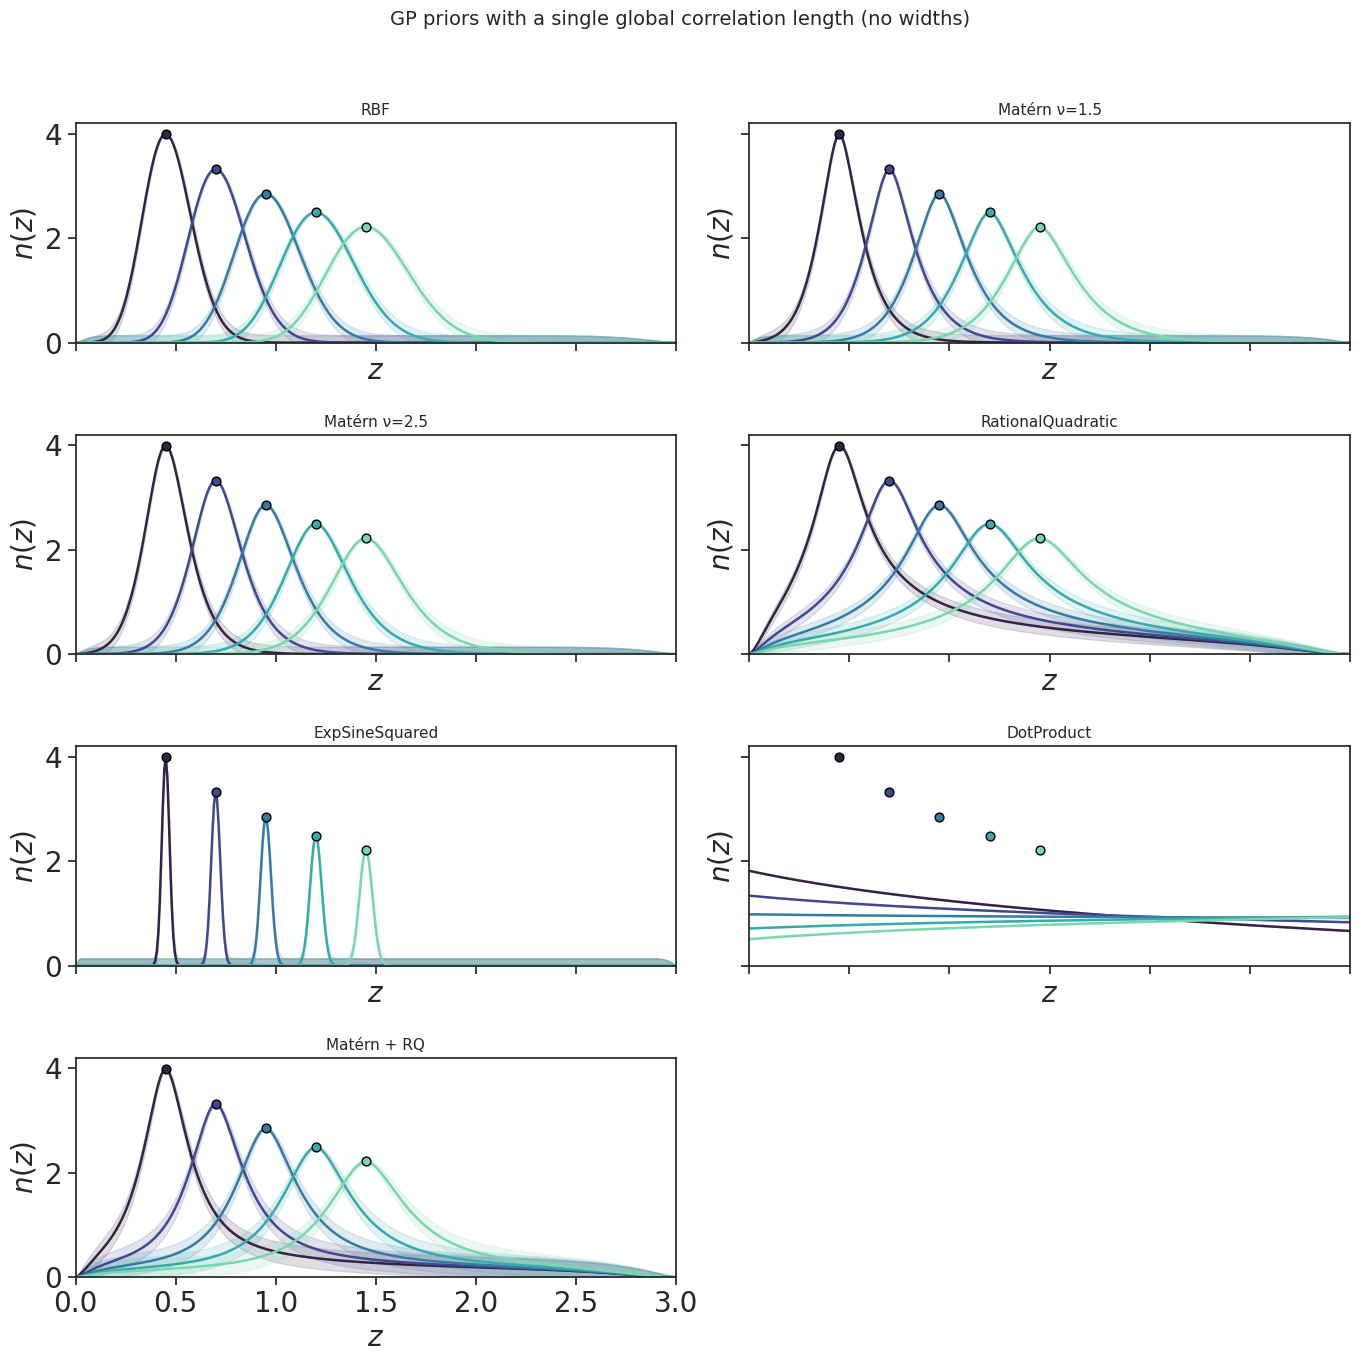

In [469]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, RationalQuadratic, ExpSineSquared,
    DotProduct, ConstantKernel as C
)
from scipy import integrate
import seaborn as sns

# -------------------------------------------------------------------------
# EXAMPLE INPUT (replace with your real n(z) dictionary)
# -------------------------------------------------------------------------
z = np.linspace(0, 3, 200)
dndz_she_norm = {}
for i in range(1, 6):  # 5 example bins
    mu = 0.2 + 0.25 * i
    sigma = 0.08 + 0.02 * i
    n = np.exp(-0.5 * ((z - mu)/sigma)**2)
    dndz_she_norm[f"bin{i}"] = n / np.trapz(n, z)

# -------------------------------------------------------------------------
# GLOBAL PARAMETERS
# -------------------------------------------------------------------------
z_min, z_max = 0.0, 3.0
z_pred = np.linspace(z_min, z_max, 400).reshape(-1, 1)

ell = 0.06         # global correlation length in normalized log-space
sigma_amp = 0.02   # GP amplitude
alpha_jitter = 1e-8

# Normalized log-space coordinate
def zx(z):
    return np.log1p(z) / np.log1p(z_max)

x_pred = zx(z_pred)

# -------------------------------------------------------------------------
# DEFINE ALL KERNELS
# -------------------------------------------------------------------------
kernel_dict = {
    "RBF": C(sigma_amp) * RBF(length_scale=ell),
    "Matérn ν=1.5": C(sigma_amp) * Matern(length_scale=ell, nu=1.5),
    "Matérn ν=2.5": C(sigma_amp) * Matern(length_scale=ell, nu=2.5),
    "RationalQuadratic": C(sigma_amp) * RationalQuadratic(length_scale=ell, alpha=0.5),
    "ExpSineSquared": C(sigma_amp) * ExpSineSquared(length_scale=ell, periodicity=1.0),
    "DotProduct": C(sigma_amp) * DotProduct(sigma_0=1.0),
    "Matérn + RQ": C(sigma_amp) * (Matern(length_scale=ell, nu=1.5) +
                                   RationalQuadratic(length_scale=ell, alpha=0.5)),
}

# -------------------------------------------------------------------------
# LOOP OVER KERNELS AND COMPUTE GP PRIORS
# -------------------------------------------------------------------------
n_kernels = len(kernel_dict)
palette = sns.color_palette("mako", len(dndz_she_norm))

fig, axs = plt.subplots(nrows=int(np.ceil(n_kernels/2)), ncols=2,
                        figsize=(14, 3.5 * int(np.ceil(n_kernels/2))),
                        sharex=True, sharey=True)
axs = axs.flatten()

for ax, (kname, kernel) in zip(axs, kernel_dict.items()):

    for j, (key, nz) in enumerate(dndz_she_norm.items()):
        # --- Compute CDF and median node ---
        cdf = integrate.cumulative_trapezoid(nz, z, initial=0)
        cdf /= cdf[-1]
        z_med = np.interp(0.5, cdf, z)
        n_med = nz[np.argmin(np.abs(z - z_med))]

        # --- Define GP with fixed kernel ---
        gp = GaussianProcessRegressor(kernel=kernel, optimizer=None,
                                      normalize_y=False, alpha=alpha_jitter)

        # --- Training nodes: boundaries + median ---
        X_train = np.array([[zx(z_min)], [zx(z_med)], [zx(z_max)]])
        y_train = np.array([0.0, n_med, 0.0])

        gp.fit(X_train, y_train)
        y_pred, y_std = gp.predict(x_pred, return_std=True)

        # --- Plot GP result ---
        ax.plot(z_pred, y_pred, color=palette[j], label=f"{key} mean", lw=1.8)
        ax.fill_between(z_pred.ravel(), (y_pred - y_std).ravel(),
                        (y_pred + y_std).ravel(), color=palette[j], alpha=0.15)
        ax.scatter(z_med, n_med, color=palette[j], edgecolor='black', s=40, zorder=3)

    ax.set_title(kname, fontsize=11)
    ax.set_xlim(z_min, z_max)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r"$z$")
    ax.set_ylabel(r"$n(z)$")

for ax in axs[len(kernel_dict):]:
    ax.axis("off")

fig.suptitle("GP priors with a single global correlation length (no widths)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
